# Figure 9 — response with the supplied NISP PSFs

Version v05 replaces the two illustrative Gaussian native PSFs with **all four
supplied NISP Y effective PSF profiles**. Each panel now shows one intrinsic
half-light radius, 0.18 or 0.35 arcsec, versus nominal input S/N 20, 50, 100.
Color and symbol identify native observed shapes, the original ResNet, and the
unchanged noiseless high-resolution control. The stronger v04 styling is retained.

The plotted response is the equally weighted mean across the four stack PSFs.
Every PSF and method uses the same objects successful in all five shear branches.
The PSFs include pixel response: native images are rendered without another pixel
convolution, following the PSFEx/GalSim convention. Input hashes, PSF sampling,
rotation, flux, and rendering controls passed before execution; an independent
reader reproduced all response matrices, ratios, and success counts afterward.

This is an idealized synthetic pilot, not calibrated shear. The 0.65-arcsec and
noiseless-input cases remain in the tables below. The displayed sizes were
selected during the earlier Gaussian experiment, before this new run. All
Gaussian versions remain archived. No training or held-out test evaluation.
The figure is a local draft, not yet installed in the manuscript.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
here=Path.cwd()
workspace=here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path: sys.path.insert(0,str(workspace))
from figure_utils import ROOT,FIGURES,style,read_json,sha,export
%matplotlib inline
style(10)
plt.rcParams.update({'text.color':'#263445','axes.labelcolor':'#263445',
                     'xtick.color':'#465465','ytick.color':'#465465'})
VERSION='v05'
source=FIGURES/'inputs/shear_response_empirical_v01.json'
b=read_json(source)
assert b['complete'] and sha(ROOT/b['report_path'])==b['report_sha256']
assert sha(ROOT/b['verification_path'])==b['verification_sha256']
assert read_json(ROOT/b['verification_path'])['passed']
assert sha(ROOT/b['protocol_path'])==b['protocol_sha256']
METHODS=[('native_observed','Native observed','#687789','o'),
         ('resnet_observed','ResNet observed','#007CC3','s'),
         ('target_observed','High-resolution control','#E18A22','^')]
RADII=[.18,.35]
SNRS=[20,50,100]
X=np.arange(3)
lookup={(r['half_light_radius'],r['snr']):r for r in b['cells']}
assert len(lookup)==12 and len(b['psfs'])==4
print('Four measured NISP PSFs; 48 cells; independent verification passed.')
print('Aggregate response = equal PSF weights on common successful objects.')

Four measured NISP PSFs; 48 cells; independent verification passed.
Aggregate response = equal PSF weights on common successful objects.


Exported: fig09_shear_response_v05.pdf, fig09_shear_response_v05.svg, fig09_shear_response_v05.png


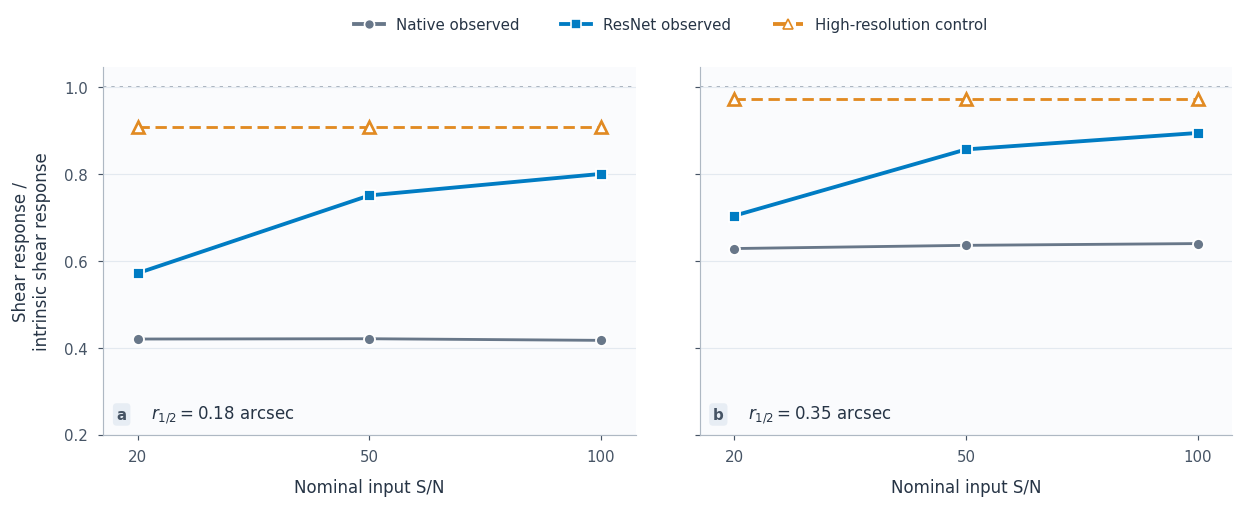

In [2]:
fig,axes=plt.subplots(1,2,figsize=(10.4,4.25),sharey=True)
plotted=[]
for ax,radius,letter in zip(axes,RADII,['a','b']):
    ax.set_facecolor('#FAFBFD')
    ax.axhline(1,color='#99A4B1',lw=1,ls=(0,(2,3)),zorder=1)
    for spine in ['left','bottom']: ax.spines[spine].set_color('#AEB8C3')
    ax.tick_params(length=3,width=.7,pad=6)
    rows=[lookup[(radius,snr)] for snr in SNRS]
    for name,label,color,marker in METHODS:
        values=np.array([r['methods'][name]['relative_trace_response'] for r in rows])
        assert np.isfinite(values).all()
        reference=name=='target_observed'
        line,=ax.plot(X,values,color=color,marker=marker,
                     ls=(0,(4,2)) if reference else '-',
                     lw=2.3 if name=='resnet_observed' else 1.7,
                     ms=7.1 if reference else 6.6,
                     mfc='white' if reference else color,
                     mec=color if reference else 'white',mew=1.6 if reference else 1.1,
                     zorder=5 if name=='resnet_observed' else 3)
        np.testing.assert_array_equal(line.get_ydata(),values)
        for r,value in zip(rows,values):
            plotted.append(dict(half_light_radius=radius,snr=r['snr'],method=name,
                response_ratio=float(value),common=r['common_success'],attempted=r['attempted'],
                psf_range=r['methods'][name]['psf_range']))
    ax.text(.035,.055,letter,transform=ax.transAxes,ha='center',va='center',
            fontsize=9,fontweight='bold',color='#465465',
            bbox=dict(boxstyle='round,pad=.25',fc='#E7EDF4',ec='none'))
    ax.text(.09,.055,rf'$r_{{1/2}}={radius:.2f}$ arcsec',transform=ax.transAxes,
            ha='left',va='center',fontsize=10)
    ax.set_xticks(X,['20','50','100'])
    ax.set_xlabel('Nominal input S/N',labelpad=8)
    ax.set_xlim(-.15,2.15);ax.set_ylim(.2,1.045)
    ax.set_yticks([.2,.4,.6,.8,1.])
    ax.grid(axis='y',color='#E3E9F0',lw=.7,zorder=0)
axes[0].set_ylabel('Shear response /\nintrinsic shear response',labelpad=8)
handles=[Line2D([],[],color=color,lw=2.3,marker=marker,ms=6,
                ls=(0,(4,2)) if name=='target_observed' else '-',
                mfc='white' if name=='target_observed' else color,
                mec=color if name=='target_observed' else 'white',label=label)
         for name,label,color,marker in METHODS]
fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.54,1.005),
           ncol=3,frameon=False,fontsize=9,columnspacing=2.8)
fig.subplots_adjust(left=.085,right=.99,bottom=.16,top=.88,wspace=.12)
assert len(plotted)==18
paths=export(fig,f'fig09_shear_response_{VERSION}','09_shear_response.ipynb',
             [source,ROOT/b['report_path'],ROOT/b['verification_path'],ROOT/b['protocol_path']],
             settings=dict(version=VERSION,panels='intrinsic half-light radius',
                 radii=RADII,snr_order=SNRS,categorical_positions=X.tolist(),
                 native_psf='All four supplied NISP Y effective profiles; no extra pixel convolution',
                 aggregation=b['aggregation'],values=plotted,
                 size_selection='0.18 and 0.35 selected in the earlier Gaussian pilot; 0.65 reported separately',
                 noiseless_input_displayed=False,native_psf_correction_displayed=False),
             status='Supplied NISP PSF synthetic pilot; original ResNet; not calibrated shear')
plt.show()

## Working caption

Shear response of observed adaptive galaxy shapes using the supplied NISP
$Y_{\rm E}$ effective PSFs. Panels (a) and (b) show exponential galaxies with
intrinsic half-light radii 0.18 and 0.35 arcsec. Gray circles, blue squares, and
orange open triangles denote native observed shapes, original ResNet outputs,
and a noiseless high-resolution control, respectively. The vertical axis is
$\mathrm{tr}(R)/\mathrm{tr}(R_{\rm intrinsic})$, where
$R_{ij}=[\langle e_i\rangle_{g_j=+0.01}-\langle e_i\rangle_{g_j=-0.01}]/0.02$.
The dotted horizontal line marks the intrinsic response. Each point is the
equally weighted mean of the responses obtained with the four supplied stack
PSFs, on an identical successful population across all PSFs, displayed methods,
and five shear branches. These PSFs replace the illustrative Gaussian native
profiles; their signed oversampled arrays are normalized, centered, and mapped
using the PSF/native header coordinate bases. The native rendering samples the
effective profile without applying detector-pixel convolution a second time.

Intrinsic distortion magnitude is 0.35. Each cell has eight orientations and
four Gaussian-noise realizations per orientation, with the same realization
reused across shear branches and PSFs. The common sample contains 31/32 objects
at radius 0.18 arcsec and S/N 20, and 32/32 in the other displayed cells. The S/N
axis is categorical; lines guide the eye. These are pilot point estimates
without uncertainty intervals. Equal PSF weights do not represent galaxy-abundance
weighting, and the four PSFs are not independent noise realizations.

The high-resolution control retains a circular Gaussian PSF of FWHM 0.08 arcsec
and high-resolution pixel integration; it is not a validated JWST simulation.
The radii were selected for stronger gains in the earlier Gaussian pilot. The
full new experiment includes radius 0.65 arcsec and noiseless native inputs,
retained in the diagnostic report; at radius 0.65 arcsec and S/N 20, ResNet still
has a weaker response than native NISP. Auxiliary native PSF-correction failures
are retained but do not select the displayed sample. No PSF correction is applied
to displayed shapes. Finite PSF stamps, linear header geometry, idealized galaxy
profiles and independent pixel noise limit realism. These responses do not
establish calibrated weak-lensing accuracy.

## All radii, noiseless inputs, and PSF variation

The table includes the two omitted categories. PSF ranges are descriptive ranges
over four supplied profiles, not confidence intervals. The simulation and
pixel-response conventions are documented in `paper/empirical_shear_protocol.md`;
all primary and auxiliary statuses remain in the frozen run report and arrays.

In [3]:
records=[]
for row in b['cells']:
    for name,label,_,_ in METHODS:
        r=row['methods'][name]
        records.append(dict(radius=row['half_light_radius'],
            snr='Noiseless' if row['snr'] is None else str(row['snr']),method=label,
            response=r['relative_trace_response'],minimum_psf=r['psf_range'][0],
            maximum_psf=r['psf_range'][1],common=row['common_success'],attempted=row['attempted']))
display(pd.DataFrame(records))
print('All 18 plotted response values checked against independently verified results.')

,radius,snr,method,response,minimum_psf,maximum_psf,common,attempted
0,0.18,Noiseless,Native observed,0.420098,0.418866,0.420766,8,8
1,0.18,Noiseless,ResNet observed,0.805883,0.804689,0.807254,8,8
2,0.18,Noiseless,High-resolution control,0.907293,0.907293,0.907293,8,8
3,0.18,20,Native observed,0.420074,0.418651,0.420735,31,32
4,0.18,20,ResNet observed,0.571616,0.571308,0.571797,31,32
5,0.18,20,High-resolution control,0.907293,0.907293,0.907294,31,32
6,0.18,50,Native observed,0.420751,0.419524,0.421433,32,32
7,0.18,50,ResNet observed,0.750553,0.749804,0.751638,32,32
8,0.18,50,High-resolution control,0.907293,0.907293,0.907293,32,32
9,0.18,100,Native observed,0.417025,0.415866,0.417700,32,32


All 18 plotted response values checked against independently verified results.
